In [ ]:
import cv2 as cv
import numpy as np
import os
from skimage.transform import resize

def get_optical_flow(file,frame_limit,matrix_shape):
    cap = cv.VideoCapture(file)

    ret, first_frame = cap.read()
    if not ret or first_frame is None:
        cap.release()
        return np.zeros((frame_limit, matrix_shape, matrix_shape, 3), dtype=np.float32)
    prev_gray = cv.cvtColor(first_frame, cv.COLOR_BGR2GRAY)

    mask = np.zeros_like(first_frame)
    mask[..., 1] = 255
   
    frame_count = 0

    flows= np.zeros((frame_limit,matrix_shape,matrix_shape,3))
    
    while(frame_count<frame_limit):
        
        ret, frame = cap.read()
        if not ret or frame is None: 
            break
        gray = cv.cvtColor(frame, cv.COLOR_BGR2GRAY)
        
        flow = cv.calcOpticalFlowFarneback(prev_gray, gray, None, 0.5, 3, 15, 3, 5, 1.2, 0) 
        magnitude, angle = cv.cartToPolar(flow[..., 0], flow[..., 1])
        
        mask[..., 0] = angle * 180 / np.pi / 2
        mask[..., 2] = cv.normalize(magnitude, None, 0, 255, cv.NORM_MINMAX)
      
        rgb = cv.cvtColor(mask, cv.COLOR_HSV2BGR)
        rgb = resize(rgb, (matrix_shape,matrix_shape))
        flows[frame_count] = rgb 

        prev_gray = gray
        frame_count +=1

    cap.release()
    flows = np.array(flows)
    
    return flows

In [22]:
yunet_model_path='../face_detection_yunet_2023mar.onnx'
detector = cv.FaceDetectorYN.create(
    model=yunet_model_path,
    config="",
    input_size=(320, 320),
    score_threshold=0.6,
    nms_threshold=0.3,
    top_k=5000
)

In [ ]:
import os
os.environ["OPENCV_LOG_LEVEL"] = "FATAL"

import cv2 as cv
import numpy as np

def get_optical_flow(file, frame_limit, matrix_shape, detector):
    cap = cv.VideoCapture(file)

    ret, first_frame = cap.read()
    if not ret or first_frame is None:
        cap.release()
        return np.zeros((frame_limit, matrix_shape, matrix_shape, 3), dtype=np.float32)

    h_img, w_img, _ = first_frame.shape
    detector.setInputSize((w_img, h_img))

    _, faces = detector.detect(first_frame)

    if faces is not None and len(faces) > 0:
        best_face = max(faces, key=lambda f: f[2] * f[3])
        x, y, w, h = map(int, best_face[:4])

        margin_x = int(0.2 * w)
        margin_y = int(0.2 * h)
        x1 = max(0, x - margin_x)
        y1 = max(0, y - margin_y)
        x2 = min(w_img, x + w + margin_x)
        y2 = min(h_img, y + h + margin_y)
    else:
        x1, y1, x2, y2 = 0, 0, w_img, h_img

    prev_gray_crop = cv.cvtColor(first_frame[y1:y2, x1:x2], cv.COLOR_BGR2GRAY)

    crop_h, crop_w = prev_gray_crop.shape
    mask = np.zeros((crop_h, crop_w, 3), dtype=np.uint8)
    mask[..., 1] = 255

    flows = np.zeros((frame_limit, matrix_shape, matrix_shape, 3), dtype=np.float32)
    frame_count = 0

    while frame_count < frame_limit:
        ret, frame = cap.read()
        if not ret or frame is None:
            break

        gray_crop = cv.cvtColor(frame[y1:y2, x1:x2], cv.COLOR_BGR2GRAY)
        flow = cv.calcOpticalFlowFarneback(prev_gray_crop, gray_crop, None, 0.5, 3, 15, 3, 5, 1.2, 0)
        magnitude, angle = cv.cartToPolar(flow[..., 0], flow[..., 1])

        mask[..., 0] = angle * 180 / np.pi / 2
        mask[..., 2] = cv.normalize(magnitude, None, 0, 255, cv.NORM_MINMAX)

        rgb = cv.cvtColor(mask, cv.COLOR_HSV2BGR)
        resized_rgb = cv.resize(rgb, (matrix_shape, matrix_shape), interpolation=cv.INTER_AREA)

        flows[frame_count] = resized_rgb.astype(np.float32) / 255.0

        prev_gray_crop = gray_crop
        frame_count += 1

    cap.release()
    return flows

In [ ]:
import os
import re
import numpy as np

def extract_video_index(filename):
    match = re.match(r'^(\d+)', filename)
    return int(match.group(1)) if match else None


def precalculate_and_save_flows(dataset_path, output_dir, face_detector, frame_limit=40, matrix_shape=100):
    """
    Brute force calculation for the whole dataset
    """
    os.makedirs(output_dir, exist_ok=True)
    folders = sorted(os.listdir(dataset_path))
    
    total_processed = 0

    for folder in folders:
        folder_path = os.path.join(dataset_path, folder)
        if not os.path.isdir(folder_path):
            continue

        files = sorted([f for f in os.listdir(folder_path) if f.endswith(('.mp4', '.avi', '.mov'))])

        method_out_dir = os.path.join(output_dir, folder)
        os.makedirs(method_out_dir, exist_ok=True)

        print(f"\n--- Working on: {folder} (len: {len(files)}) ---")

        for idx, filename in enumerate(files):
            vid_path = os.path.join(folder_path, filename)
            save_name = os.path.splitext(filename)[0] + '.npy'
            save_path = os.path.join(method_out_dir, save_name)

            if os.path.exists(save_path):
                continue

            flow_data = get_optical_flow(vid_path, frame_limit, matrix_shape, face_detector)
            np.save(save_path, flow_data.astype(np.float32))
            total_processed += 1
            if total_processed % 50 == 0:
                print(f"Progress: {total_processed}")

    print("\nOptical flow done")


def precalculate_and_save_flows_one(dataset_path, output_dir, face_detector, target_method, frame_limit=40, matrix_shape=100):
    """
    For only 1 method + do not calculate flow it file exists
    """
    method_folder_path = os.path.join(dataset_path, target_method)
    
    if not os.path.exists(method_folder_path) or not os.path.isdir(method_folder_path):
        print(f"Not found^ '{target_method}' ({method_folder_path})")
        return

    method_out_dir = os.path.join(output_dir, target_method)
    os.makedirs(method_out_dir, exist_ok=True)
    files = sorted([f for f in os.listdir(method_folder_path) if f.endswith(('.mp4', '.avi', '.mov'))])
    
    print(f"==================================================")
    print(f"MEthod: [{target_method}]")
    print(f"Total videos: {len(files)}")
    print(f"Output: {method_out_dir}")
    print(f"==================================================")

    total_processed = 0
    total_skipped = 0

    for idx, filename in enumerate(files):
        vid_path = os.path.join(method_folder_path, filename)
        save_name = os.path.splitext(filename)[0] + '.npy'
        save_path = os.path.join(method_out_dir, save_name)

        if os.path.exists(save_path):
            total_skipped += 1
            continue


        flow_data = get_optical_flow(vid_path, frame_limit, matrix_shape, face_detector)
        np.save(save_path, flow_data.astype(np.float32))
        total_processed += 1

        if total_processed % 25 == 0:
            print(f"[{target_method}] processed {total_processed} / {len(files) - total_skipped}")

    print(f"\n======= Done")
    print("Method: {target_method}")
    print(f"Newly calculated {total_processed}")
    print(f"Was already calculated: {total_skipped}")

In [ ]:
DATASET_PATH = '../datasets/FaceForensics++_C23'
PROCESSED_FLOWS_PATH = '../datasets/Flow'

for mtd in ["DeepFakeDetection", "Deepfakes", "Face2Face", "FaceShifter", "FaceSwap", "NeuralTextures"]:
    precalculate_and_save_flows_one(DATASET_PATH, PROCESSED_FLOWS_PATH, detector, mtd, frame_limit=32, matrix_shape=50)

In [ ]:
def load_lomo_npy_splits(processed_dir, lomo_holdout_method):
    splits = {
        'train': {'x': [], 'y': []},
        'val':   {'x': [], 'y': []},
        'test':  {'x': [], 'y': []},
        'eval':  {'x': [], 'y': []}
    }

    folders = sorted(os.listdir(processed_dir))

    for folder in folders:
        folder_path = os.path.join(processed_dir, folder)
        if not os.path.isdir(folder_path):
            continue

        label = 0 if folder == 'original' else 1
        files = sorted([f for f in os.listdir(folder_path) if f.endswith('.npy')])
        total_files = len(files)

        for idx, filename in enumerate(files):
            file_path = os.path.join(folder_path, filename)

            if folder == lomo_holdout_method:
                splits['eval']['x'].append(file_path)
                splits['eval']['y'].append(label)
            elif folder == 'DeepFakeDetection':
                ratio = idx / total_files
                if ratio < 0.80:
                    target = 'train'
                elif ratio < 0.95:
                    target = 'val'
                else:
                    target = 'test'
                splits[target]['x'].append(file_path)
                splits[target]['y'].append(label)
            else:
                vid_idx = extract_video_index(filename)
                if vid_idx is None:
                    vid_idx = idx

                if vid_idx < 800:
                    target = 'train'
                elif vid_idx < 950:
                    target = 'val'
                else:
                    target = 'test'

                splits[target]['x'].append(file_path)
                splits[target]['y'].append(label)

    for s in splits:
        splits[s]['x'] = np.array(splits[s]['x'])
        splits[s]['y'] = np.array(splits[s]['y'])

    return splits

In [ ]:
def balanced_npy_generator(npy_paths, labels, batch_size=16, shuffle=True):
    real_indices = np.where(labels == 0)[0]
    fake_indices = np.where(labels == 1)[0]
    
    half_batch = batch_size // 2

    while True:
        if shuffle:
            np.random.shuffle(real_indices)
            np.random.shuffle(fake_indices)

        for i in range(0, max(len(real_indices), len(fake_indices)), half_batch):
            batch_real_idx = [real_indices[(i + j) % len(real_indices)] for j in range(half_batch)]
            batch_fake_idx = [fake_indices[(i + j) % len(fake_indices)] for j in range(half_batch)]

            batch_indices = np.concatenate([batch_real_idx, batch_fake_idx])

            if shuffle:
                np.random.shuffle(batch_indices)

            batch_paths = npy_paths[batch_indices]
            batch_y = labels[batch_indices]
            batch_x = [np.load(p) for p in batch_paths]

            yield np.array(batch_x, dtype=np.float32), np.array(batch_y)


def sequential_npy_generator(npy_paths, labels, batch_size=16):
    num_samples = len(npy_paths)

    while True:
        for i in range(0, num_samples, batch_size):
            batch_paths = npy_paths[i : i + batch_size]
            batch_y = labels[i : i + batch_size]

            batch_x = [np.load(p) for p in batch_paths]

            yield np.array(batch_x, dtype=np.float32), np.array(batch_y)

In [ ]:
PROCESSED_FLOWS_PATH = '../datasets/Flow'

splits = load_lomo_npy_splits(PROCESSED_FLOWS_PATH, lomo_holdout_method='DeepFakeDetection')
val_gen = sequential_npy_generator(splits['val']['x'], splits['val']['y'], batch_size=16)


# import time
# start = time.time()
# x_batch, y_batch = next(val_gen)
# print(f"{time.time() - start:.4f}c") 

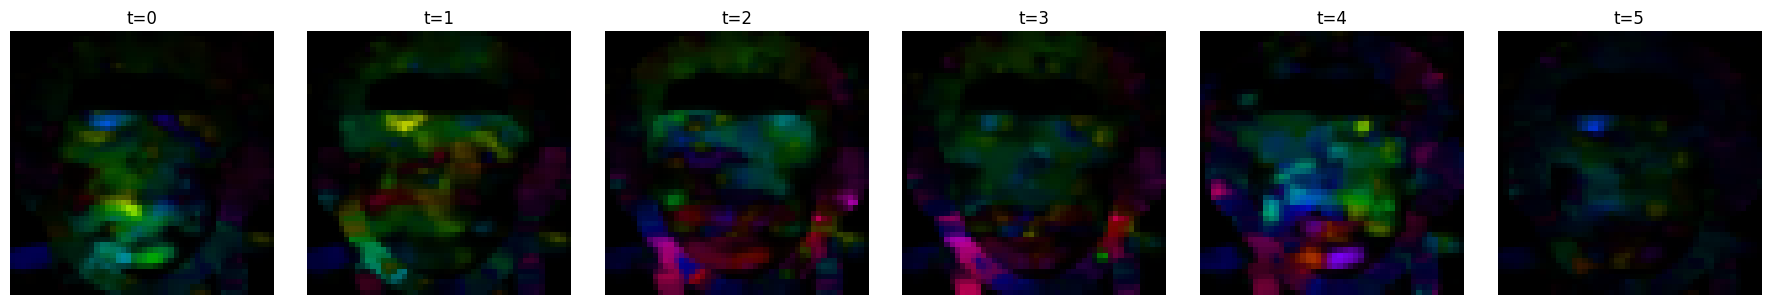

In [21]:
import matplotlib.pyplot as plt

b = 15
num_show = 6

plt.figure(figsize=(18, 3))
for k in range(num_show):
    img = x_batch[b, k]
    img = np.clip(img, 0, 1)

    ax = plt.subplot(1, num_show, k+1)
    ax.imshow(img)
    ax.set_title(f"t={k}")
    ax.axis('off')

plt.tight_layout()
plt.show()